LAB 7 - CDS 230
Dae yeong Mun, Dong hyun Park

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("dry_bean_clean.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df.info())
print(df.isnull().sum())

Dataset shape: (13611, 17)
    Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRation  \
0  28395    610.291       208.178117       173.888747      1.197191   
1  28734    638.018       200.524796       182.734419      1.097356   
2  29380    624.110       212.826130       175.931143      1.209713   
3  30008    645.884       210.557999       182.516516      1.153638   
4  30140    620.134       201.847882       190.279279      1.060798   

   Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  roundness  \
0      0.549812       28715     190.141097  0.763923  0.988856   0.958027   
1      0.411785       29172     191.272750  0.783968  0.984986   0.887034   
2      0.562727       29690     193.410904  0.778113  0.989559   0.947849   
3      0.498616       30724     195.467062  0.782681  0.976696   0.903936   
4      0.333680       30417     195.896503  0.773098  0.990893   0.984877   

   Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4  Class  
0  

In [ ]:
# Step 2 - Explore Features and Labels

features = [col for col in df.columns if col != 'Class']

print('Number of features:', len(features))
print('Feature names:', features)

print('\nLabel distribution:')
print(df['Class'].value_counts().sort_index())

Number of features: 16
Feature names: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Label distribution:
Class
BARBUNYA    1322
BOMBAY       522
CALI        1630
DERMASON    3546
HOROZ       1928
SEKER       2027
SIRA        2636
Name: count, dtype: int64


In [ ]:
# Step 3 - Standardize Features

from sklearn.preprocessing import StandardScaler

X = df[features]
y = df['Class']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original data shape:", X.shape)
print("Standardized data shape:", X_scaled.shape)

print("\nMean after scaling:")
print(X_scaled.mean(axis=0).round(2))

print("\nStandard deviation after scaling:")
print(X_scaled.std(axis=0).round(2))

Original data shape: (13611, 16)
Standardized data shape: (13611, 16)

Mean after scaling:
[ 0. -0. -0.  0.  0. -0.  0. -0. -0. -0.  0.  0. -0.  0.  0. -0.]

Standard deviation after scaling:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
# Step 4 - Apply PCA

from sklearn.decomposition import PCA

# Reduce 16 features to 2 principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("PCA transformed shape:", X_pca.shape)

print("\nExplained Variance Ratio:")
print("PC1:", round(pca.explained_variance_ratio_[0], 4))
print("PC2:", round(pca.explained_variance_ratio_[1], 4))

print("\nTotal Explained Variance:")
print(round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

Original shape: (13611, 16)
PCA transformed shape: (13611, 2)

Explained Variance Ratio:
PC1: 0.5547
PC2: 0.2643

Total Explained Variance:
81.9 %


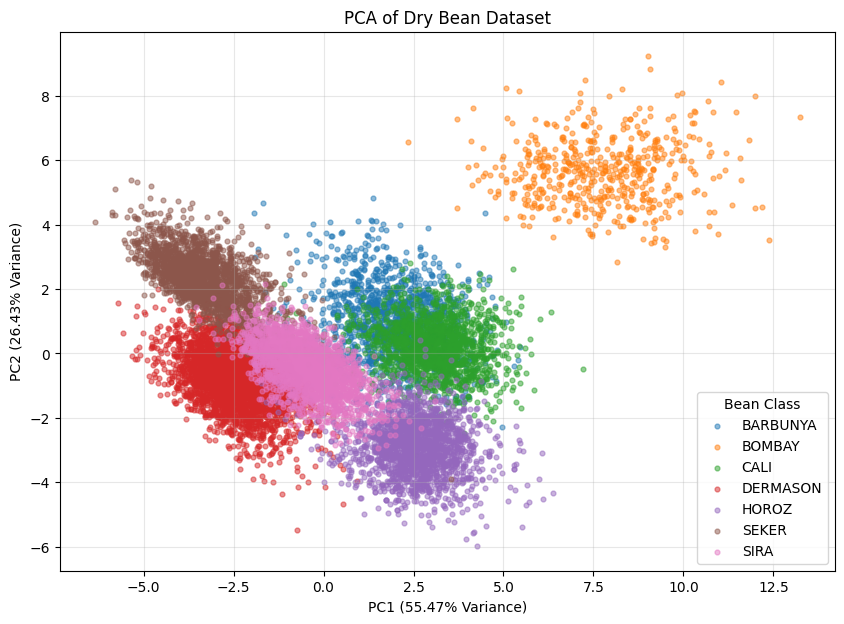

In [ ]:
# Step 5 - Visualize PCA Results

import matplotlib.pyplot as plt
import pandas as pd

# Create PCA DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

pca_df['Class'] = y.values

# Plot PCA results
plt.figure(figsize=(10, 7))

for bean_class in sorted(pca_df['Class'].unique()):
    subset = pca_df[pca_df['Class'] == bean_class]

    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        label=bean_class,
        alpha=0.5,
        s=12
    )

plt.xlabel('PC1 (55.47% Variance)')
plt.ylabel('PC2 (26.43% Variance)')
plt.title('PCA of Dry Bean Dataset')
plt.legend(title='Bean Class')
plt.grid(alpha=0.3)
plt.show()

### PCA Results and Interpretation – Dry Bean Dataset

In this analysis, we used the Dry Bean dataset, which contains 13,611 samples and 16 numerical features. The goal was to reduce the number of features while keeping as much information as possible.

First, we standardized the data using StandardScaler. Then, we applied Principal Component Analysis (PCA) to reduce the 16 features to two principal components.

The first principal component (PC1) explained 55.47% of the total variance, while the second principal component (PC2) explained 26.43%. Together, they explained 81.90% of the total variance.

The scatter plot shows that some bean types are clearly separated, especially BOMBAY. However, other types, such as SIRA and DERMASON, overlap in some areas.

Overall, PCA helped us simplify a complex dataset into a two-dimensional graph while preserving most of the variation in the data. It also made it easier to understand similarities and differences between bean types.

Dataset link : https://archive.ics.uci.edu/dataset/602/dry+bean+dataset